In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

# ---- Code from the previous chapters ----
def relu(z):
    return np.maximum(0, z)

def relu_prime(z):
    return (z > 0).astype(float)

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def init_params(sizes, seed=0):
    rng = np.random.default_rng(seed)
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        W = rng.normal(0, np.sqrt(2 / n_in), (n_out, n_in))
        b = np.zeros(n_out)
        params.append([W, b])
    return params

def forward(params, X):
    H = X
    cache = [(None, X)]
    for l, (W, b) in enumerate(params):
        Z = H @ W.T + b
        H = softmax(Z) if l == len(params) - 1 else relu(Z)
        cache.append((Z, H))
    return H, cache

def cross_entropy(Y_hat, Y):
    return -np.mean(np.sum(Y * np.log(Y_hat + 1e-12), axis=1))

def backward(params, cache, Y):
    N = Y.shape[0]
    grads = [None] * len(params)
    Delta = (cache[-1][1] - Y) / N
    for l in reversed(range(len(params))):
        W, b = params[l]
        H_prev = cache[l][1]
        grads[l] = [Delta.T @ H_prev, Delta.sum(axis=0)]
        if l > 0:
            Delta = (Delta @ W) * relu_prime(cache[l][0])
    return grads

def accuracy(Y_hat, y):
    return np.mean(Y_hat.argmax(axis=1) == y)

In [2]:
def train_sgd(params, X, Y, y, lr=1e-2, batch_size=32, epochs=10, seed=0):
    """
    Trains the MLP with mini-batch SGD.
    params: list of [W, b]. The initial parameters (modified in-place).
    X, Y, y: the dataset (inputs, one-hot labels, integer labels).
    lr: the learning rate. Either a float, or a function k -> eta_k.
    """
    rng = np.random.default_rng(seed)
    N = X.shape[0]
    k = 0
    loss_hist, acc_hist, time_hist = [], [], []
    start = time.time()

    for epoch in range(epochs):
        # Shuffle the dataset
        idx = rng.permutation(N)

        for start_batch in range(0, N, batch_size):
            # Select the batch M_k
            batch_idx = idx[start_batch:start_batch + batch_size]
            Xb, Yb = X[batch_idx], Y[batch_idx]

            # Stochastic gradient (forward + backward pass on the batch)
            Y_hat, cache = forward(params, Xb)
            grads = backward(params, cache, Yb)

            # SGD update
            eta = lr(k) if callable(lr) else lr
            for (W, b), (dW, db) in zip(params, grads):
                W -= eta * dW
                b -= eta * db
            k += 1

        # Log full-dataset metrics after each epoch
        Y_hat, _ = forward(params, X)
        loss_hist.append(cross_entropy(Y_hat, Y))
        acc_hist.append(accuracy(Y_hat, y))
        time_hist.append(time.time() - start)

    return params, np.array(loss_hist), np.array(acc_hist), np.array(time_hist)

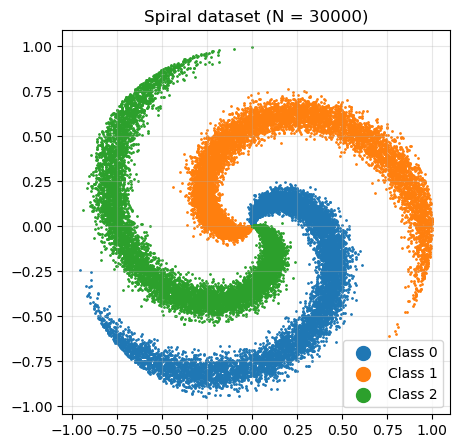

In [3]:
def make_spirals(N, K=3, noise=0.2, seed=0):
    """
    Generates N points in R^2 on K intertwined spirals (one per class).
    """
    rng = np.random.default_rng(seed)
    n = N // K
    X = np.zeros((n * K, 2))
    y = np.zeros(n * K, dtype=int)
    for k in range(K):
        r = np.linspace(0.0, 1, n)                                        # radius
        t = np.linspace(k * 4, (k + 1) * 4, n) + noise * rng.normal(size=n)  # angle
        X[k * n:(k + 1) * n] = np.stack([r * np.sin(t), r * np.cos(t)], axis=1)
        y[k * n:(k + 1) * n] = k
    return X, y

X, y = make_spirals(30000)
Y = np.eye(3)[y]
N = X.shape[0]

plt.figure(figsize=(5, 5))
for k in range(3):
    plt.scatter(X[y == k, 0], X[y == k, 1], s=1, label=f"Class {k}")
plt.legend(markerscale=10)
plt.gca().set_aspect("equal")
plt.title(f"Spiral dataset (N = {N})")
plt.grid(alpha=0.3)
plt.show()

N_batch =     1: relative error of the average stochastic gradient = 0.272
N_batch =     4: relative error of the average stochastic gradient = 0.099
N_batch =    16: relative error of the average stochastic gradient = 0.026
N_batch =    64: relative error of the average stochastic gradient = 0.015
N_batch =   256: relative error of the average stochastic gradient = 0.016
N_batch =  1024: relative error of the average stochastic gradient = 0.006


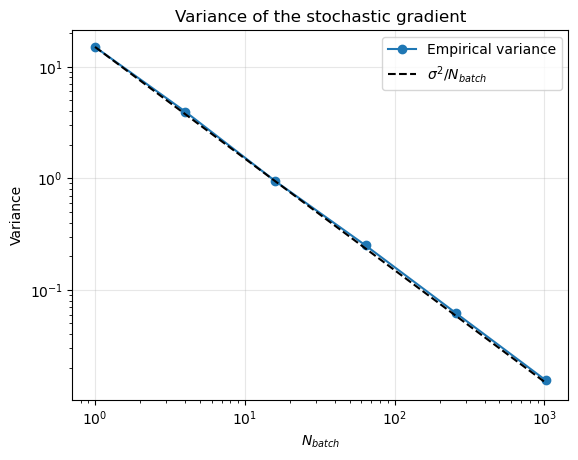

In [4]:
def flatten(grads):
    """Concatenates all the gradients in a single vector."""
    return np.concatenate([g.ravel() for layer in grads for g in layer])

params = init_params([2, 64, 64, 3], seed=0)

# True gradient (on the whole dataset)
Y_hat, cache = forward(params, X)
true_grad = flatten(backward(params, cache, Y))

rng = np.random.default_rng(0)
batch_sizes = [1, 4, 16, 64, 256, 1024]
mean_err, variances = [], []
for bs in batch_sizes:
    sg = []
    for _ in range(300):
        batch_idx = rng.choice(N, bs, replace=True)
        Y_hat, cache = forward(params, X[batch_idx])
        sg.append(flatten(backward(params, cache, Y[batch_idx])))
    sg = np.array(sg)
    mean_err.append(np.linalg.norm(sg.mean(axis=0) - true_grad) / np.linalg.norm(true_grad))
    variances.append(np.mean(np.sum((sg - true_grad)**2, axis=1)))

for bs, e in zip(batch_sizes, mean_err):
    print(f"N_batch = {bs:5d}: relative error of the average stochastic gradient = {e:.3f}")

plt.loglog(batch_sizes, variances, 'o-', label="Empirical variance")
plt.loglog(batch_sizes, variances[0] / np.array(batch_sizes), 'k--', label=r"$\sigma^2 / N_{batch}$")
plt.xlabel(r"$N_{batch}$")
plt.ylabel("Variance")
plt.title("Variance of the stochastic gradient")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [5]:
epochs = 30
configs = [(N, 0.5), (256, 0.1), (64, 0.1), (16, 0.05)]  # (batch size, learning rate)
results = {}

for bs, lr in configs:
    params = init_params([2, 64, 64, 3], seed=0)
    params, loss_hist, acc_hist, time_hist = train_sgd(params, X, Y, y, lr=lr,
                                                       batch_size=bs, epochs=epochs)
    name = "GD" if bs == N else f"SGD ($N_{{batch}}$ = {bs})"
    results[name] = (params, loss_hist, acc_hist, time_hist)
    print(f"{name:25s}: iterations = {epochs * int(np.ceil(N / bs)):6d}, final loss = {loss_hist[-1]:.4f}, "
          f"final accuracy = {acc_hist[-1]*100:.2f}%, time = {time_hist[-1]:.2f}s")

GD                       : iterations =     30, final loss = 0.3764, final accuracy = 92.53%, time = 1.59s


SGD ($N_{batch}$ = 256)  : iterations =   3540, final loss = 0.0239, final accuracy = 99.59%, time = 2.20s


SGD ($N_{batch}$ = 64)   : iterations =  14070, final loss = 0.0109, final accuracy = 99.68%, time = 2.53s


SGD ($N_{batch}$ = 16)   : iterations =  56250, final loss = 0.0095, final accuracy = 99.68%, time = 4.47s


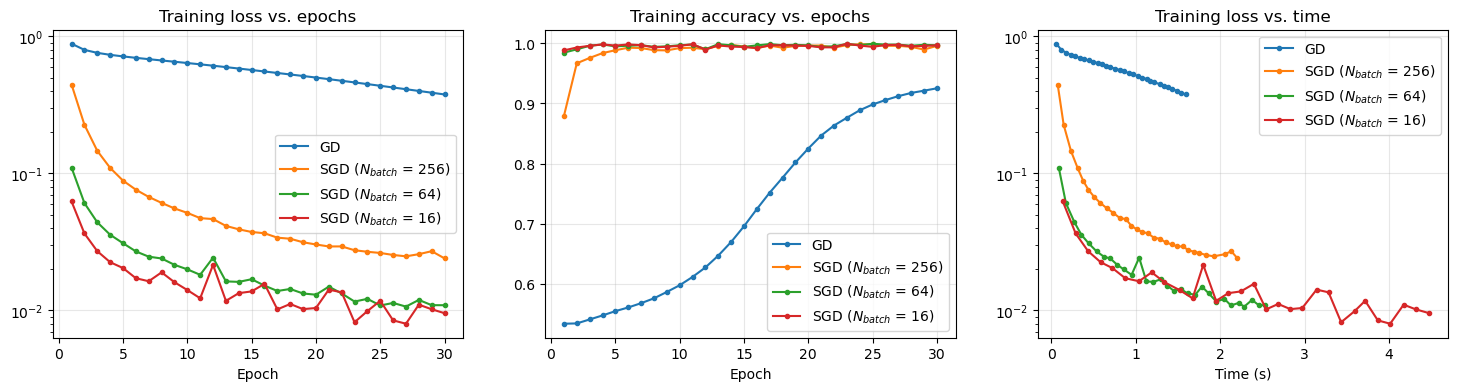

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for name, (_, loss_hist, acc_hist, time_hist) in results.items():
    axes[0].semilogy(np.arange(1, epochs + 1), loss_hist, 'o-', ms=3, label=name)
    axes[1].plot(np.arange(1, epochs + 1), acc_hist, 'o-', ms=3, label=name)
    axes[2].semilogy(time_hist, loss_hist, 'o-', ms=3, label=name)

axes[0].set_title("Training loss vs. epochs")
axes[0].set_xlabel("Epoch")
axes[1].set_title("Training accuracy vs. epochs")
axes[1].set_xlabel("Epoch")
axes[2].set_title("Training loss vs. time")
axes[2].set_xlabel("Time (s)")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()

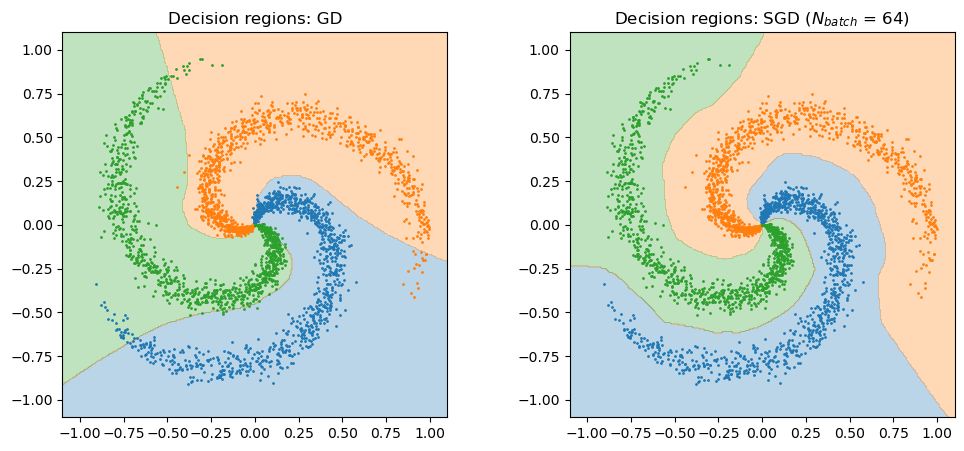

In [7]:
xx1, xx2 = np.meshgrid(np.linspace(-1.1, 1.1, 300), np.linspace(-1.1, 1.1, 300))
grid = np.stack([xx1.ravel(), xx2.ravel()], axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ["GD", "SGD ($N_{batch}$ = 64)"]):
    params = results[name][0]
    P_grid, _ = forward(params, grid)
    ax.contourf(xx1, xx2, P_grid.argmax(axis=1).reshape(xx1.shape), levels=[-0.5, 0.5, 1.5, 2.5],
                colors=["tab:blue", "tab:orange", "tab:green"], alpha=0.3)
    for k in range(3):
        ax.scatter(X[y == k, 0][::10], X[y == k, 1][::10], s=1)
    ax.set_title(f"Decision regions: {name}")
    ax.set_aspect("equal")
plt.show()

Constant       : final loss = 0.0114, final accuracy = 99.47%


Inverse decay  : final loss = 0.0108, final accuracy = 99.94%


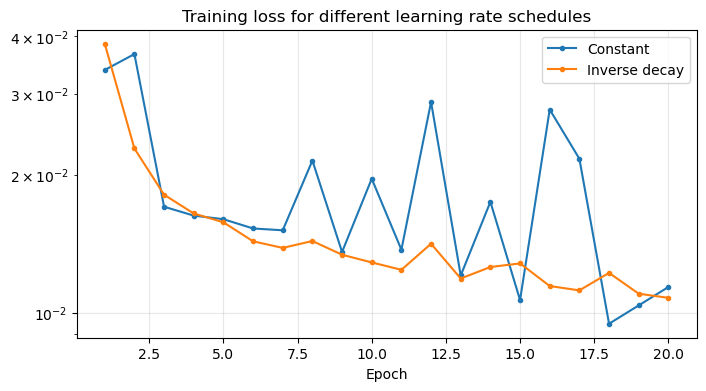

In [8]:
eta0 = 0.2
iters_per_epoch = int(np.ceil(N / 16))
schedules = {
    "Constant": eta0,
    "Inverse decay": lambda k: eta0 / (1 + k / iters_per_epoch),  # gamma = 1 / iters_per_epoch
}

plt.figure(figsize=(8, 4))
for name, lr in schedules.items():
    params = init_params([2, 64, 64, 3], seed=0)
    params, loss_hist, acc_hist, _ = train_sgd(params, X, Y, y, lr=lr, batch_size=16, epochs=20)
    print(f"{name:15s}: final loss = {loss_hist[-1]:.4f}, final accuracy = {acc_hist[-1]*100:.2f}%")
    plt.semilogy(np.arange(1, 21), loss_hist, 'o-', ms=3, label=name)
plt.xlabel("Epoch")
plt.title("Training loss for different learning rate schedules")
plt.grid(alpha=0.3)
plt.legend()
plt.show()